<table style="width: 100%;">
  <tr>
    <td style="text-align: left; vertical-align: middle;">
        <h1 style="margin: 0;">Deep Learning's Assignment 4</h1>
        <h4 style="margin: 0;">Prof. Bahrak</h4>
        <h4 style="margin: 0;">Authors: Erfan Ahmadi, Mohammad Ali Olama</h4>
        <h4 style="margin: 0;">[Group work]</h4>
    </td>
    <td style="text-align: right; vertical-align: middle;">
      <img src="https://media.porsline.ir/images/1642313491sktwifppujekhvh" alt="CC" width="1000">
    </td>
  </tr>
</table>



# Question 2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Libraries and imports


In [ ]:
from tensorflow import keras
from sklearn.metrics import confusion_matrix
import seaborn as sns
import tensorflow as tf
import os
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization, LeakyReLU, Reshape, Conv2DTranspose, Conv2D, Dropout, Flatten, GlobalAveragePooling2D, GlobalMaxPooling2D
from tensorflow.keras.models import Model, Sequential
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report
import plotly.express as px
import pandas as pd

from glob import glob
from PIL import Image
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

## Download dataset

In [ ]:
# unzip '/content/drive/MyDrive/TEIAS/Deep/HW5/data/Dataset.zip' silently

!unzip -q '/content/drive/MyDrive/TEIAS/Deep/HW5/data/Dataset.zip'

replace Dataset/Class 1/0.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


## Config

In [ ]:
IMG_HEIGHT, IMG_WIDTH, CHANNELS = 32, 32, 1
NOISE_DIM = 500
SEED = tf.random.normal([16, NOISE_DIM])

BATCH_SIZE = 16
EPOCHS = 100
D_STEPS = 2  # Train discriminator every 2 steps
SAVE_EVERY = 10

tf.random.set_seed(42)
np.random.seed(42)


## Load Images

In [ ]:
def load_images_from_folder(folder):
    image_paths = glob(f"{folder}/**/*.*", recursive=True)
    images = []
    for path in tqdm(image_paths):
        img = Image.open(path).convert('L')
        img = img.resize((IMG_WIDTH, IMG_HEIGHT))
        img = np.array(img).astype("float32")
        img = (img/ 127.5) - 1      # normalize images in range (-1 , 1), since we are using tanh in generator!
        img = np.expand_dims(img, axis=-1)
        images.append(img)
    return np.array(images)

train_imgs = load_images_from_folder("Dataset")
# shuffle train_imgs
np.random.shuffle(train_imgs)
train_ds = tf.data.Dataset.from_tensor_slices(train_imgs).batch(BATCH_SIZE)

  0%|          | 0/1005 [00:00<?, ?it/s]

Let's visualize some samples:

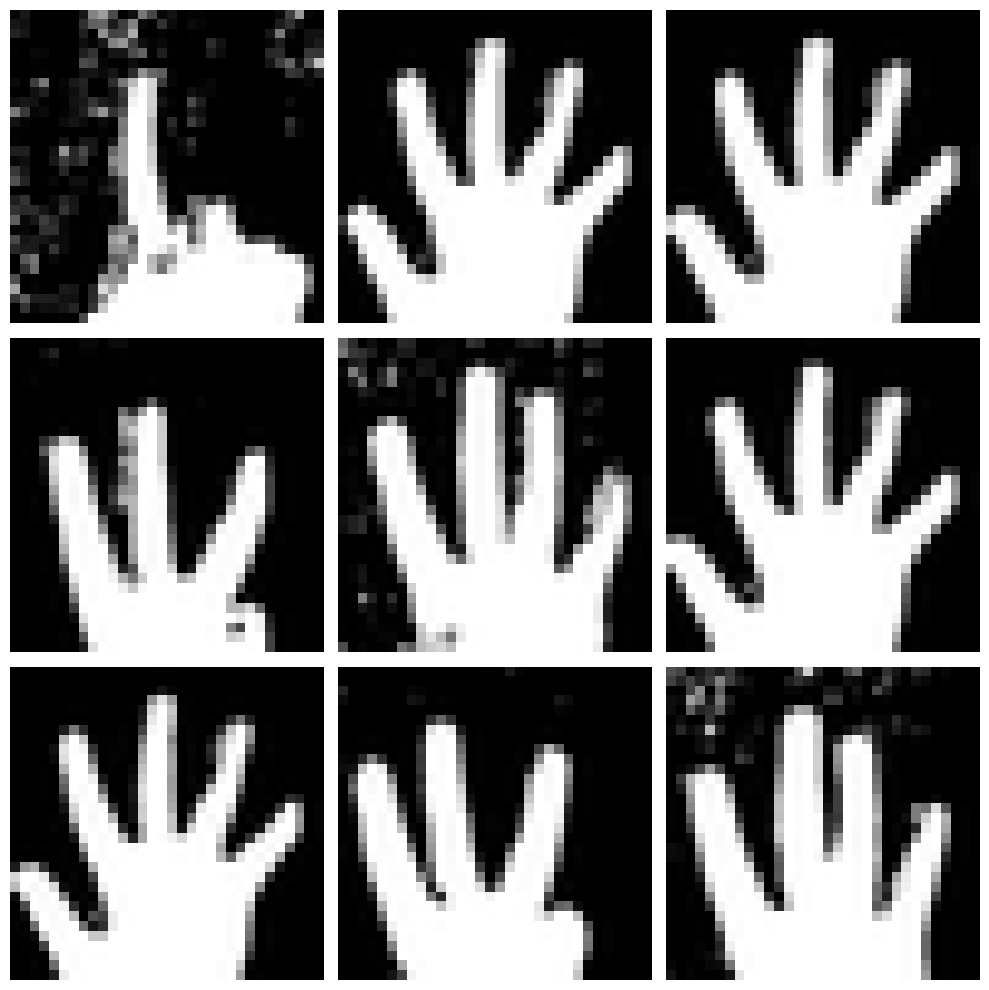

In [ ]:
import matplotlib.pyplot as plt

# Get one batch of images and labels
# images, labels = next(train_ds)

# Plot first 9 images
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(train_imgs[i].squeeze(), cmap='gray')
    # plt.title(f"Label: {int(labels[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()


## Q2.1

Let's define generator and discriminator classes:

### Generator

In [ ]:

# Generator (deeper and more expressive)
def make_generator():
    model = keras.Sequential([
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(4 * 4 * 512, use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),

        layers.Reshape((4, 4, 512)),

        layers.Conv2DTranspose(256, 5, strides=2, padding='same', use_bias=False),
        layers.ReLU(),

        layers.Conv2DTranspose(128, 5, strides=2, padding='same', use_bias=False),
        layers.ReLU(),

        layers.Conv2DTranspose(64, 5, strides=2, padding='same', use_bias=False),
        layers.ReLU(),

        layers.Conv2DTranspose(1, 5, strides=1, padding='same', activation='tanh')
    ])
    return model


generator = make_generator()
generator.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 8192)           │     4,096,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8192)           │        32,768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 8, 8, 256)      │     3,276,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 16, 16, 128)    │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 32, 32, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 32, 32, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,431,169 (32.16 MB)

 Trainable params: 8,414,785 (32.10 MB)

 Non-trainable params: 16,384 (64.00 KB)

### Discriminator

For the discriminator, we can include an optional layer.
This layer is used to apply `Mini-bath Discrimination` technique, which will prevent the generator to generate simmilar outputs every time.

**Minibatch Discrimination**

Minibatch Discrimination is a technique used in GANs to help the discriminator detect if the generator is producing similar (low-diversity) outputs, i.e., mode collapse.

**How it works:**
Each sample is compared to other samples in the same minibatch. The layer learns a tensor $T$ that projects the input features into a lower-dimensional space. The L1 distance between projected samples is calculated and converted into similarity scores. These scores are aggregated to create extra features representing how unique each sample is compared to others.

**Formula (simplified):**
1. $M_i = x_i \cdot T$, reshaped to $(\text{num_kernels}, \text{kernel_dim})$
2. $c_{ij} = \sum_{k} \exp(-||M_i^k - M_j^k||_1)$
3. $o_i = \sum_{j \neq i} c_{ij}$

Final output = original input concatenated with $o_i$

**Effect:**
Encourages the generator to produce diverse outputs by allowing the discriminator to penalize similarity across samples in the same batch.


**Minibatch Discrimination Formula Explanation**

Given a batch of input features $x_i \in \mathbb{R}^A$ for $i = 1, \dots, N$ (where $N$ is the batch size and $A$ is the feature size), the Minibatch Discrimination layer works as follows:

1. **Linear Projection:**

Each input $x_i$ is projected using a learned tensor $T \in \mathbb{R}^{A \times (B \cdot C)}$ into a new space:

$$
M_i = x_i \cdot T
$$

Then $M_i$ is reshaped to a matrix of shape $(B, C)$, where:
- $B$ is the number of kernels,
- $C$ is the kernel dimension.

2. **Compute Pairwise Distances:**

For each pair of samples $i, j$ in the batch, compute the L1 distance between their projected features (for each kernel $b$):

$$
L_{ij}^b = \sum_{c=1}^{C} |M_i^{b, c} - M_j^{b, c}|
$$

3. **Similarity Measure:**

Convert the distances into similarity scores using a negative exponential:

$$
c_{ij}^b = \exp(-L_{ij}^b)
$$

4. **Aggregation:**

Sum the similarities for each sample across the batch (excluding self-similarity $j = i$):

$$
o_i^b = \sum_{j \ne i} c_{ij}^b
$$

5. **Final Output:**

The values $o_i^b$ (one for each kernel $b$) are concatenated with the original input features:

$$
\text{Output}(x_i) = \text{concat}(x_i, o_i^1, o_i^2, \dots, o_i^B)
$$

This gives the network access to batch-level statistics, enabling it to detect if many samples are too similar.


In [ ]:
from tensorflow.keras.layers import Layer
import tensorflow.keras.backend as K

class MinibatchDiscrimination(Layer):
    def __init__(self, num_kernel=100, dim_kernel=5, **kwargs):
        super(MinibatchDiscrimination, self).__init__(**kwargs)
        self.num_kernels = num_kernel
        self.kernel_dim = dim_kernel

    def build(self, input_shape):
        self.T = self.add_weight(
            name='T',
            shape=(int(input_shape[1]), self.num_kernels * self.kernel_dim),
            initializer='glorot_uniform',
            trainable=True
        )
        super(MinibatchDiscrimination, self).build(input_shape)

    def call(self, x):
        M = K.dot(x, self.T)
        M = K.reshape(M, (-1, self.num_kernels, self.kernel_dim))
        M_exp = K.expand_dims(M, 3)
        M_diff = M_exp - K.permute_dimensions(M_exp, [3, 1, 2, 0])
        abs_diff = K.sum(K.abs(M_diff), axis=2)
        minibatch_features = K.sum(K.exp(-abs_diff), axis=2)
        return K.concatenate([x, minibatch_features], axis=1)


Now the discriminator class can use this optional feature.

In [ ]:
def make_discriminator(use_mini_batch_disc = False):
    model = keras.Sequential()

    # Input layer
    model.add(layers.Input(shape=(32, 32, 1)))

    # First Conv block
    model.add(layers.Conv2D(64, 5, strides=2, padding='same'))
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    # Second Conv block
    model.add(layers.Conv2D(128, 5, strides=2, padding='same'))
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    # Flatten and Minibatch Discrimination
    model.add(layers.Flatten())
    if use_mini_batch_disc:
      model.add(MinibatchDiscrimination(num_kernel=100, dim_kernel=5))

    # Output layer (no activation)
    model.add(layers.Dense(1))

    return model

discriminator = make_discriminator()
discriminator.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         8,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 214,785 (839.00 KB)

 Trainable params: 214,785 (839.00 KB)

 Non-trainable params: 0 (0.00 B)

### Loss and optimizer

Since we have a binary classification (real vs fake), we will use binary cross entropy as loss function.

For the disc_loss, we can apply One-sided label smoothing technique.

**One-sided Label Smoothing**

One-sided label smoothing is a regularization technique used in training GANs, applied only to the real labels in the discriminator.

**How it works:**
Instead of labeling real samples as 1, they are labeled as a value slightly less than 1 (e.g., 0.9). Fake samples are still labeled as 0.

**Effect of One-sided Label Smoothing**

1. **Prevents Overconfidence in the Discriminator:**
   - Without smoothing, the discriminator can quickly become too confident (outputting values near 1 for real data).
   - This causes vanishing gradients for the generator because the discriminator provides little useful feedback.
   - Smoothing the real labels (e.g., from 1 to 0.9) reduces this overconfidence, keeping gradients informative for longer.

2. **Reduces Sharp Gradients:**
   - Hard targets (like exact 1 or 0) can lead to large, unstable gradients.
   - Smoothed labels reduce the loss sensitivity, making the training signal smoother and more stable.

3. **Improves Generalization:**
   - Training with soft labels encourages the discriminator to be slightly uncertain, which improves its ability to generalize to unseen data rather than memorizing the training set.

4. **Slows Down Discriminator Domination:**
   - In early GAN training, the discriminator can quickly overpower the generator.
   - Label smoothing slightly weakens the discriminator's learning signal, giving the generator more time to improve and reducing the risk of early collapse.

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# generator loss is the opposite of disc loss. Since it should generate realistic images,
# its loss is low, if disc predictions are all be 1 (real image label).
def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

# disc loss is low, if it could predict 0 for fake images, and 1 for real images.
# we apply One-sided label smoothing here for disc, to prevent it from becoming overconfident and dominant.
def discriminator_loss(real_output, fake_output, label_smoothing = False):

    smoother = 1.0
    if label_smoothing:
      smoother = 0.9
    real_labels = tf.ones_like(real_output) * smoother
    fake_labels = tf.zeros_like(fake_output)
    real_loss = cross_entropy(real_labels, real_output)
    fake_loss = cross_entropy(fake_labels, fake_output)
    return real_loss + fake_loss

## Utils

In [ ]:
# Noise seed for visualization
seed = tf.random.normal([16, NOISE_DIM])

# Optimizers
# in our experiments, the disc became quickly dominant, so we decided to use a lower learning_rate for disc.
gen_optimizer = tf.keras.optimizers.RMSprop(learning_rate=1e-4)
disc_optimizer = tf.keras.optimizers.RMSprop(learning_rate=1e-5)



For the training step, we have seperate phases for generator and discriminator, as we know!

In [ ]:
from sklearn.metrics import accuracy_score

@tf.function
def generator_train_step(discriminator , generator, real_images , generator_optimizer):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])     # generate noise
    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise, training=True)  # give the noise to generator to generate fake images
        fake_output = discriminator(generated_images, training=True)  # give fake images to discriminator and calculate loss
        g_loss = generator_loss(fake_output)
    gradients = gen_tape.gradient(g_loss, generator.trainable_variables)    # apply gradient
    generator_optimizer.apply_gradients(zip(gradients, generator.trainable_variables))
    return g_loss


**Adding Noise in GANs**

Adding noise is a stabilization technique used during GAN training, typically applied to the inputs of the discriminator. Small random noise (usually Gaussian) is added to real and/or fake images before passing them to the discriminator.

**Effect:**
1. **Prevents Overfitting in the Discriminator:**
   - The discriminator can memorize exact training examples. Noise forces it to generalize rather than overfit.

2. **Regularizes Training:**
   - Introduces uncertainty that mimics real-world data variation. Leads to smoother decision boundaries.

3. **Slows Down Discriminator:**
   - Makes the discriminator's job slightly harder, giving the generator more useful gradients.

4. **Improves Robustness:**
   - The generator must learn to produce samples that are realistic even under noise, improving output quality.


In [ ]:
@tf.function
def discriminator_train_step(discriminator, generator, real_images ,discriminator_optimizer, add_noise = False , label_smoothing=False):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])     # generate noise
    generated_images = generator(noise, training=True)    # give the noise to generator to generate fake images


    if add_noise:
      real_images += tf.random.normal(tf.shape(real_images), mean=0.0, stddev=0.05)
      generated_images += tf.random.normal(tf.shape(generated_images), mean=0.0, stddev=0.05)

    # give real and fake images to discriminator. It should be able to distinguish between fake and real images.
    with tf.GradientTape() as disc_tape:
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)
        d_loss = discriminator_loss(real_output, fake_output , label_smoothing)

        # Convert logits to probabilities
        real_probs = tf.sigmoid(real_output)
        fake_probs = tf.sigmoid(fake_output)

        # Real labels = 1, Fake labels = 0
        real_preds = tf.cast(real_probs >= 0.5, tf.float32)
        fake_preds = tf.cast(fake_probs < 0.5, tf.float32)

        d_accuracy = tf.reduce_mean(tf.cast(tf.equal(real_preds, 1.0), tf.float32))
        f_accuracy = tf.reduce_mean(tf.cast(tf.equal(fake_preds, 1.0), tf.float32))



    gradients = disc_tape.gradient(d_loss, discriminator.trainable_variables)   # apply loss to update gradients
    discriminator_optimizer.apply_gradients(zip(gradients, discriminator.trainable_variables))

    return d_loss, d_accuracy, f_accuracy

# given a constant noise, use this function to generate images using generator during training.
def generate_and_save_images(model, test_input):
    predictions = model(test_input, training=False)
    return predictions




The main body of our training process is the following cell. Notice that the discriminator is trained every 2 epochs:

In [ ]:
# Training loop
def train(discriminator, generator, generator_optimizer , discriminator_optimizer, dataset, epochs , use_smoothing = False , add_noise = False):
    gen_losses, disc_losses = [], []
    disc_real_acc , disc_fake_acc = [], []
    generator_generated_images = []
    step = 0
    for epoch in range(epochs):
      g_epoch_loss, d_epoch_loss = [], []
      d_epoch_accuracy, f_epoch_accuracy = [], []
      pbar = tqdm(dataset, desc=f"Epoch {epoch+1}/{epochs}")
      for batch in pbar:
          # Train discriminator only every D_STEPS. This is done since in our experiments,
          # the discriminator become too powerful and dominates the generator almost always.
          if step % D_STEPS == 0:
              d_loss , d_accuracy, f_accuracy = discriminator_train_step(discriminator , generator, batch , discriminator_optimizer, add_noise, use_smoothing )
          else:
              d_loss , d_accuracy, f_accuracy = np.nan , np.nan , np.nan

          # Train generator every epoch.
          g_loss = generator_train_step(discriminator , generator, batch, generator_optimizer)

          g_epoch_loss.append(g_loss.numpy())
          d_epoch_loss.append(d_loss)
          d_epoch_accuracy.append(d_accuracy)
          f_epoch_accuracy.append(f_accuracy)

          pbar.set_postfix({
              "G_loss": f"{g_loss.numpy():.4f}",
              "D_loss": f"{d_loss if isinstance(d_loss, float) else d_loss.numpy():.4f}",
              "D_acc": f"{d_accuracy if isinstance(d_accuracy, float) else d_accuracy.numpy():.4f}",
              "F_acc": f"{f_accuracy if isinstance(f_accuracy, float) else f_accuracy.numpy():.4f}"
          })

      ggg = generate_and_save_images(generator, seed)   # generate and save a sample for this epoch.
      generator_generated_images.append(ggg)
      gen_losses.append(np.mean(g_epoch_loss))
      disc_losses.append(np.mean(d_epoch_loss))
      disc_real_acc.append(np.mean(d_epoch_accuracy))
      disc_fake_acc.append(np.mean(f_epoch_accuracy))
      step += 1
    return gen_losses, disc_losses, disc_real_acc, disc_fake_acc, generator_generated_images

Now, let's train gen and disc, without using any stabilization technique:

In [ ]:
gen_losses, disc_losses, disc_real_acc, disc_fake_acc, generator_generated_images = train(discriminator , generator, gen_optimizer , disc_optimizer, train_ds, EPOCHS)

Epoch 1/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 2/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 3/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 4/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 5/100:   0%|          | 0/63 [00:00<?, ?it/s]

...

Epoch 96/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 97/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 98/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 99/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 100/100:   0%|          | 0/63 [00:00<?, ?it/s]

### Plot loss

In [ ]:
# remove np.nan values from disc_losses, since we train disc every 2 steps.

import numpy as np
disc_losses = [loss for loss in disc_losses if not np.isnan(loss)]
disc_real_acc = [acc for acc in disc_real_acc if not np.isnan(acc)]
disc_fake_acc = [acc for acc in disc_fake_acc if not np.isnan(acc)]


In [ ]:
len(disc_real_acc)

50

In [ ]:
print(len(gen_losses))
print(len(disc_losses))

100
50


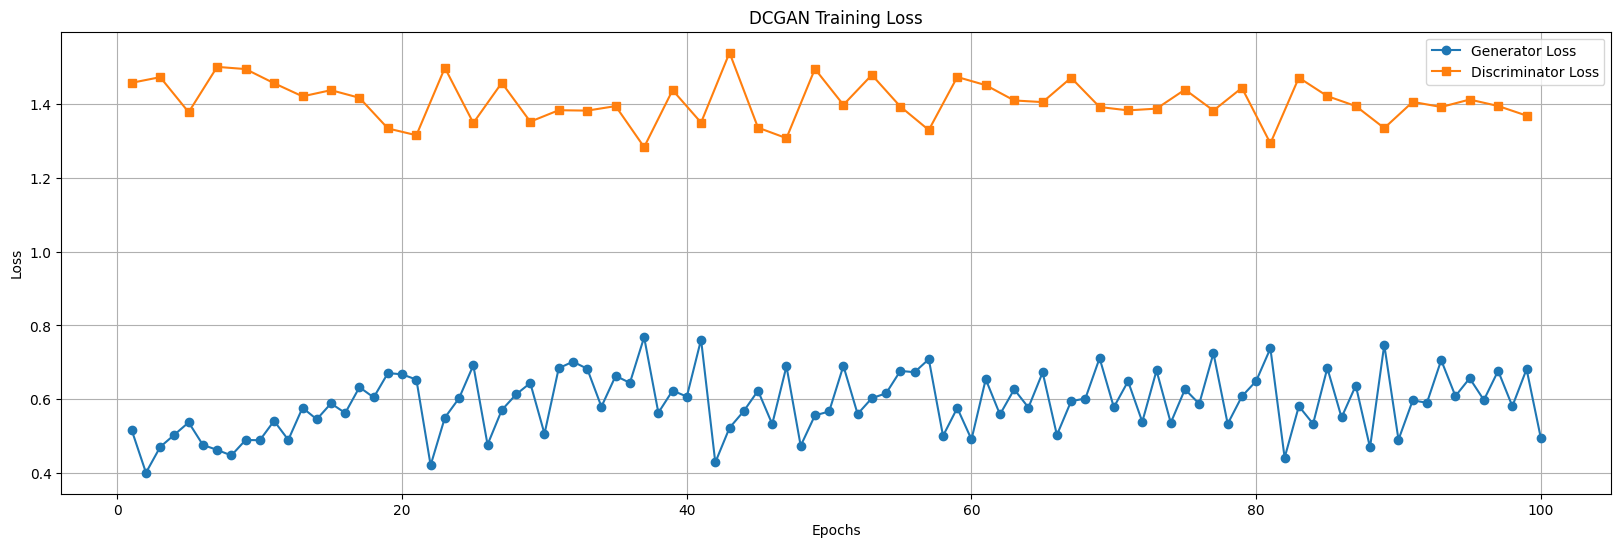

In [ ]:
import matplotlib.pyplot as plt

# Corresponding epochs
epochs_full = list(range(1, len(gen_losses)+1))
epochs_sparse = list(range(1, len(gen_losses)+1, 2))


# ========== Plot Loss ==========
plt.figure(figsize=(20, 6))
plt.plot(epochs_full, gen_losses, label="Generator Loss" , marker = 'o')
plt.plot(epochs_sparse, disc_losses, label="Discriminator Loss" , marker = 's')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")
# plt.xticks(range(1, len(gen_losses)+1))  # Ensure x-axis shows all epochs from 1 to 10
plt.legend()
plt.grid(True)
plt.savefig("loss_curve.png")
plt.show()



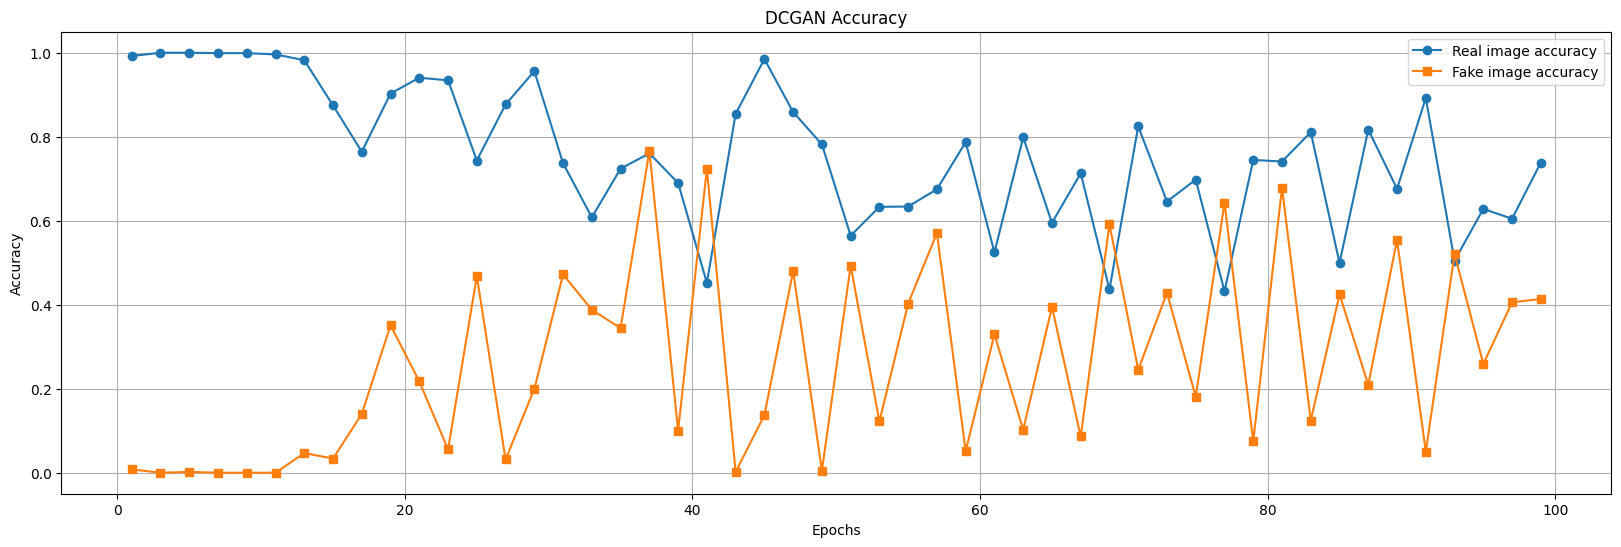

In [ ]:
import matplotlib.pyplot as plt

# Corresponding epochs
epochs_full = list(range(1, len(gen_losses)+1))

epochs_sparse = list(range(1, len(gen_losses)+1, 2))


# disc_real_acc, disc_fake_acc
plt.figure(figsize=(20, 6))
plt.plot(epochs_sparse, disc_real_acc, label="Real image accuracy" , marker = 'o')
plt.plot(epochs_sparse, disc_fake_acc, label="Fake image accuracy" , marker = 's')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("DCGAN Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("loss_curve.png")
plt.show()



In [ ]:
def generate_and_show_images(model, test_input):
    # os.makedirs(save_dir, exist_ok=True)
    predictions = model(test_input, training=False)
    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)
        img = tf.squeeze(predictions[i], axis=-1)
        plt.imshow(img * 0.5 + 0.5, cmap='gray')
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    # plt.savefig(f"{save_dir}/image_epoch_{epoch:03d}.png")
    # plt.close()

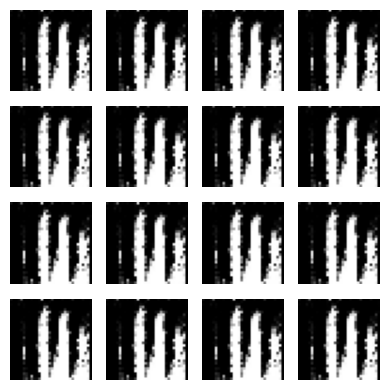

In [ ]:
generate_and_show_images(generator, seed)

Mode collapse! The generator learns a specific distribution that fools the discriminator.

In [ ]:
def plot_sample(generator_generated_images, ind=0):
  res = []
  for i in range(len(generator_generated_images)):
    res.append(generator_generated_images[i][ind])

  plt.figure(figsize=(5, 5))
  plt.title(f"Sample {ind}")
  for i in range(100):
      plt.subplot(10, 10, i + 1)
      img = tf.squeeze(res[i], axis=-1)
      plt.imshow(img * 0.5 + 0.5, cmap='gray')
      plt.axis('off')
  plt.tight_layout()
  plt.show()
  # generate_and_show_images(generator, generator_generated_images[i])

# generator_generated_images[0][0].shape

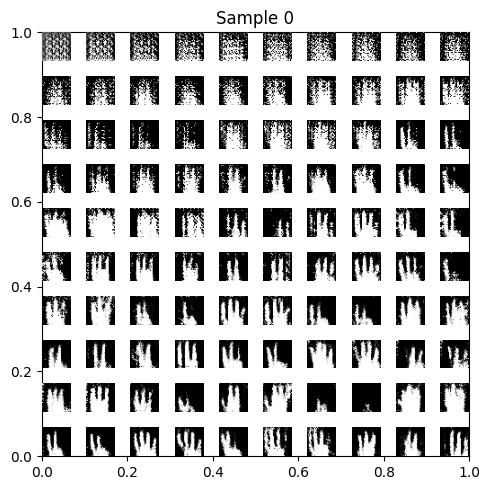

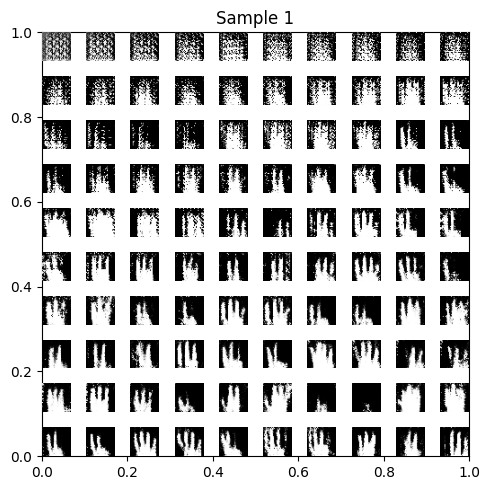

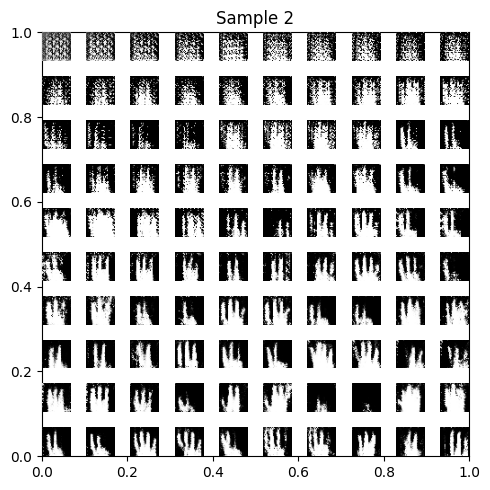

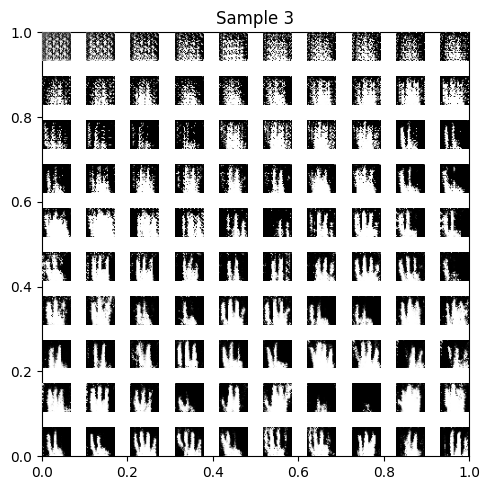

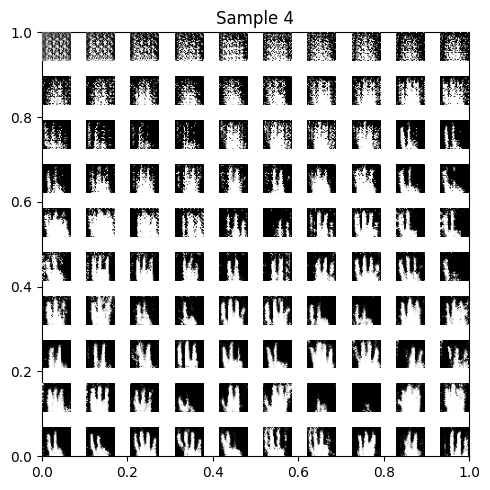

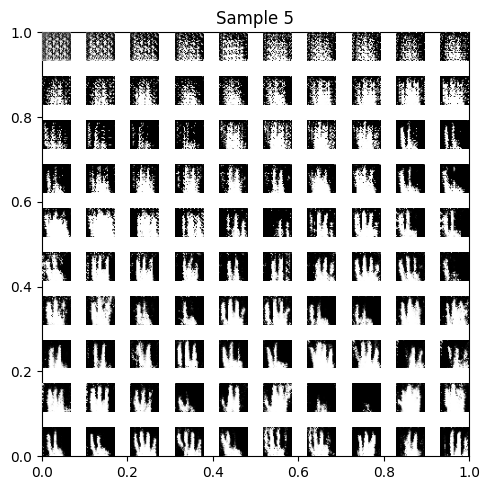

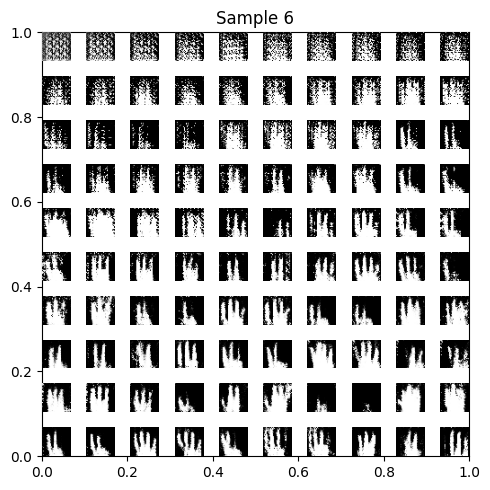

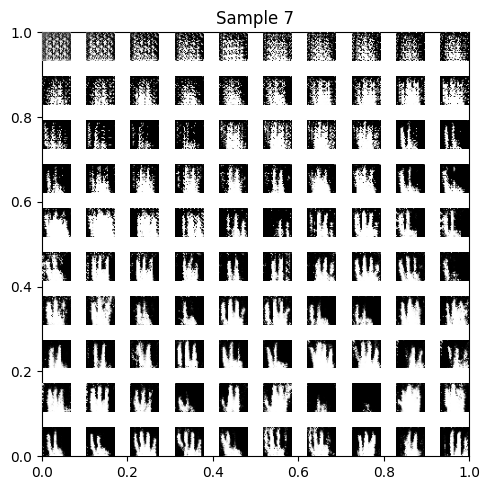

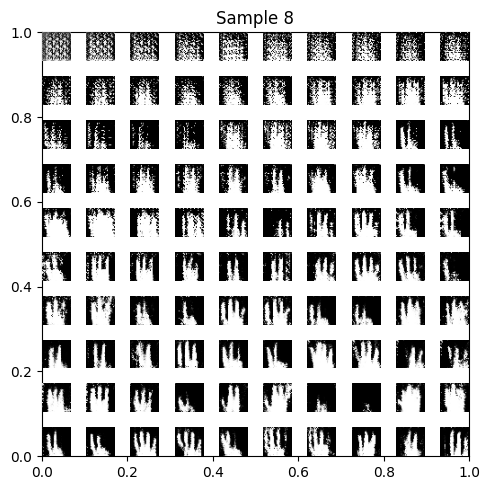

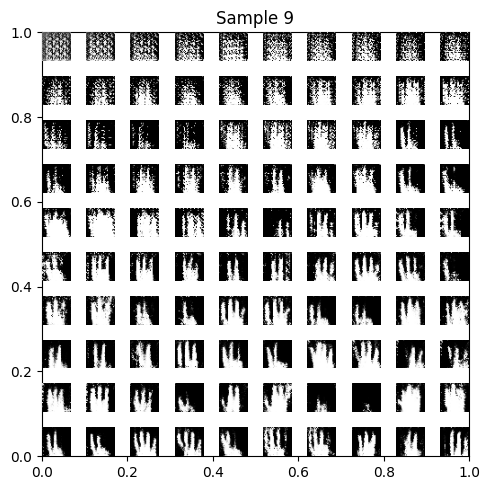

In [ ]:
for i in range(10):
  plot_sample(generator_generated_images, i)
# plot_sample(1)

The above plot shows the learning process of the generator. As it it obvious, in early epochs it usually generates noisy images, and then it learns to generate meaningful images step by step.

## Q2.3

Now, let's train the models again. This time we will use stabilization techniques:

* Label smoothing
* Add noise
* Mini-batch discrimination (You didn't want this in the assingment, but it is very helpful!)

In [ ]:
generator2 = make_generator()
generator2.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 8192)           │     4,096,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8192)           │        32,768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 8, 8, 256)      │     3,276,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 16, 16, 128)    │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_10 (ReLU)                 │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 32, 32, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_11 (ReLU)                 │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 32, 32, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,431,169 (32.16 MB)

 Trainable params: 8,414,785 (32.10 MB)

 Non-trainable params: 16,384 (64.00 KB)

In [ ]:
discriminator2 = make_discriminator(use_mini_batch_disc=True)
discriminator2.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ minibatch_discrimination_1      │ (None, 8292)           │     4,096,000 │
│ (MinibatchDiscrimination)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │         8,293 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,310,885 (16.44 MB)

 Trainable params: 4,310,885 (16.44 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Optimizers
gen_optimizer2 = tf.keras.optimizers.RMSprop(learning_rate=1e-4)
disc_optimizer2 = tf.keras.optimizers.RMSprop(learning_rate=1e-5)


In [ ]:
gen_losses2, disc_losses2, disc_real_acc2, disc_fake_acc2, generator_generated_images2 = train(discriminator2 , generator2, gen_optimizer2 , disc_optimizer2, train_ds, EPOCHS , use_smoothing = True , add_noise = True)

Epoch 1/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 2/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 3/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 4/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 5/100:   0%|          | 0/63 [00:00<?, ?it/s]

...

Epoch 96/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 97/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 98/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 99/100:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 100/100:   0%|          | 0/63 [00:00<?, ?it/s]

In [ ]:

import numpy as np
disc_losses2 = [loss for loss in disc_losses2 if not np.isnan(loss)]
disc_real_acc2 = [acc for acc in disc_real_acc2 if not np.isnan(acc)]
disc_fake_acc2 = [acc for acc in disc_fake_acc2 if not np.isnan(acc)]

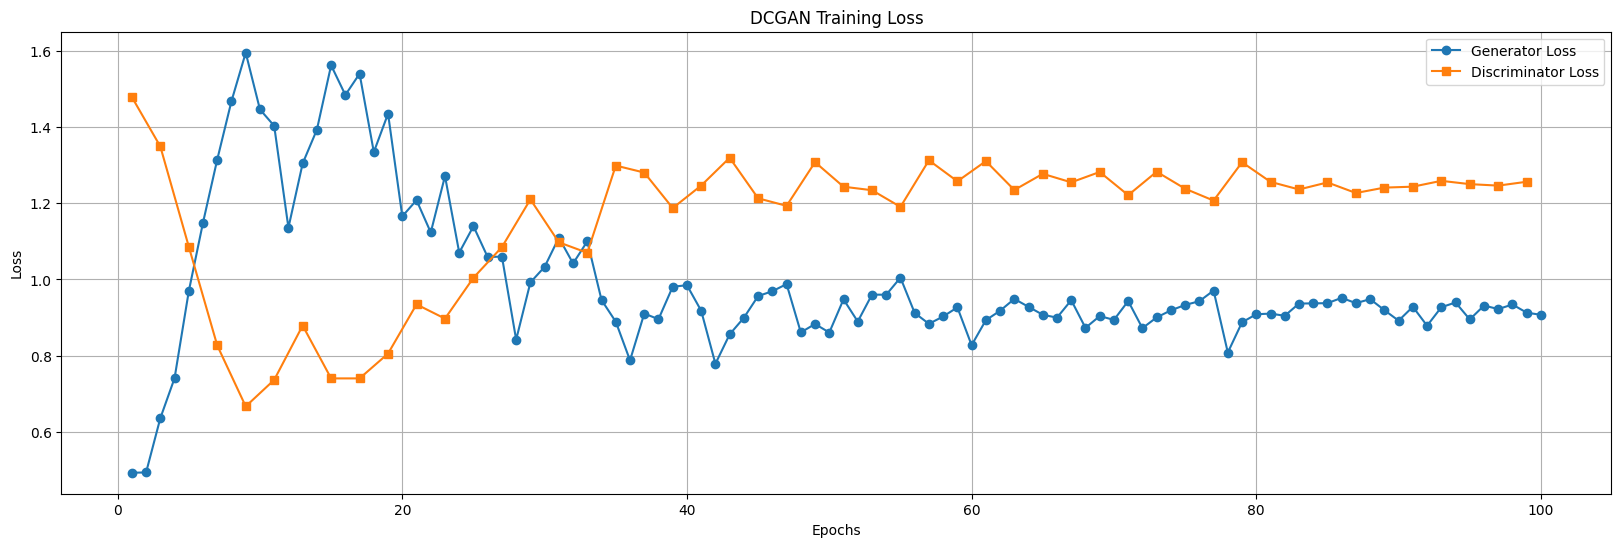

In [ ]:
import matplotlib.pyplot as plt

# Corresponding epochs
epochs_full = list(range(1, len(gen_losses2)+1))
epochs_sparse = list(range(1, len(gen_losses2)+1, 2))


# ========== Plot Loss ==========
plt.figure(figsize=(20, 6))
plt.plot(epochs_full, gen_losses2, label="Generator Loss" , marker = 'o')
plt.plot(epochs_sparse, disc_losses2, label="Discriminator Loss" , marker = 's')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")
# plt.xticks(range(1, len(gen_losses)+1))  # Ensure x-axis shows all epochs from 1 to 10
plt.legend()
plt.grid(True)
plt.savefig("loss_curve.png")
plt.show()



As you can see, it seems that the generator now challenges the discriminator. The loss of discriminator rises over time, showing that the generator makes more realistic images.

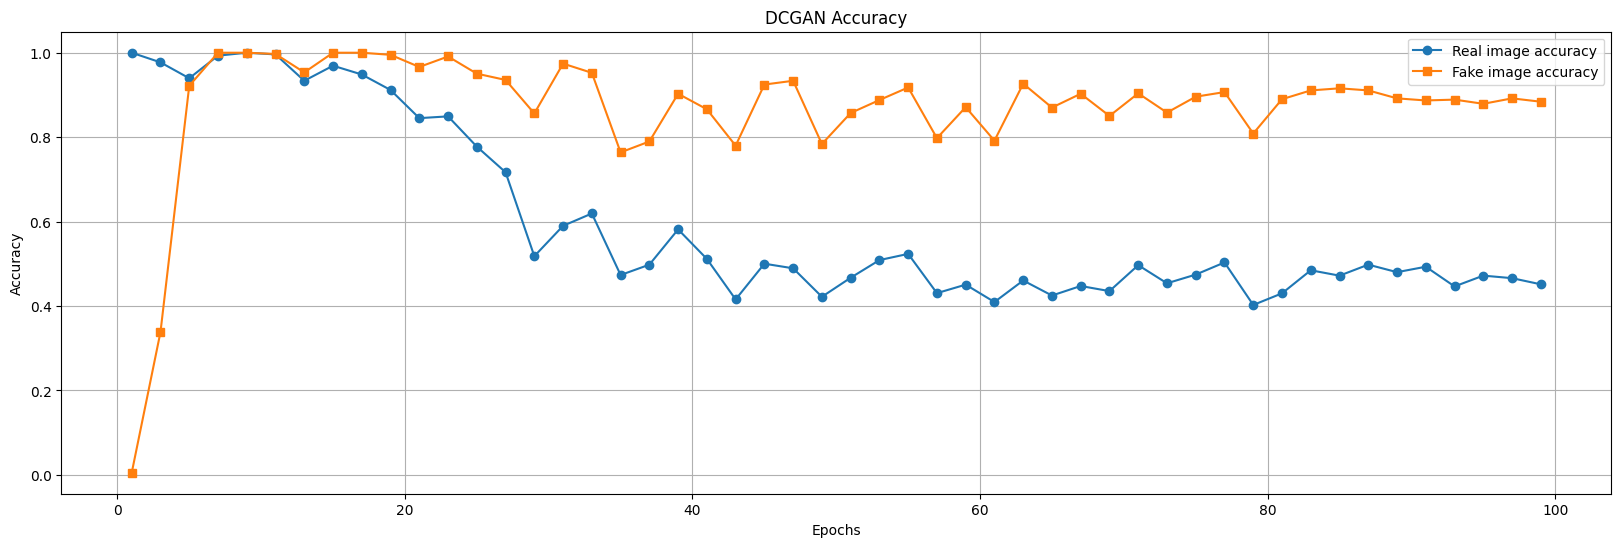

In [ ]:
import matplotlib.pyplot as plt

# Corresponding epochs
epochs_full = list(range(1, len(gen_losses2)+1))

epochs_sparse = list(range(1, len(gen_losses2)+1, 2))


# disc_real_acc, disc_fake_acc
# ========== Plot Loss ==========
plt.figure(figsize=(20, 6))
plt.plot(epochs_sparse, disc_real_acc2, label="Real image accuracy" , marker = 'o')
plt.plot(epochs_sparse, disc_fake_acc2, label="Fake image accuracy" , marker = 's')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("DCGAN Accuracy")
# plt.xticks(range(1, len(gen_losses)+1))  # Ensure x-axis shows all epochs from 1 to 10
plt.legend()
plt.grid(True)
plt.savefig("loss_curve.png")
plt.show()



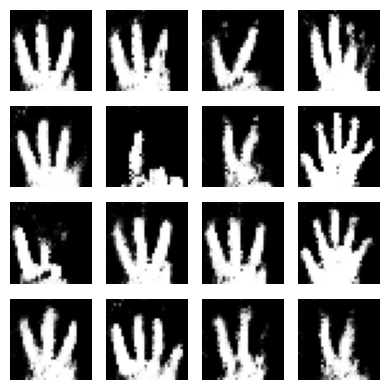

In [ ]:
generate_and_show_images(generator2, seed)

Despite the first experiment where generator had "mode collapse", now it produces a variety of images.

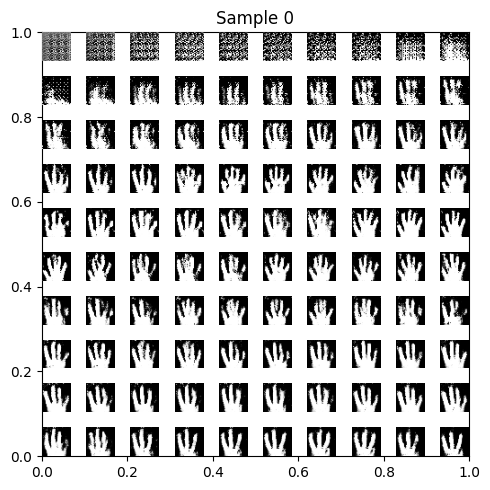

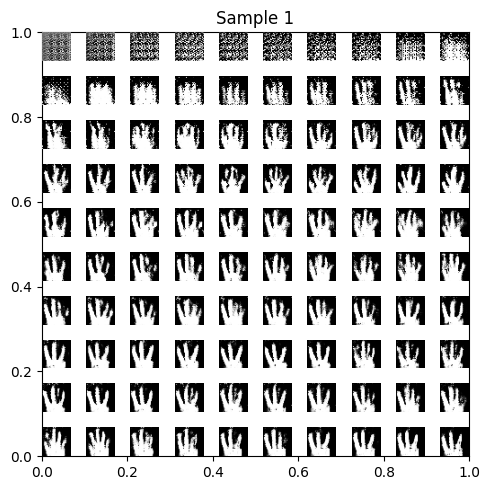

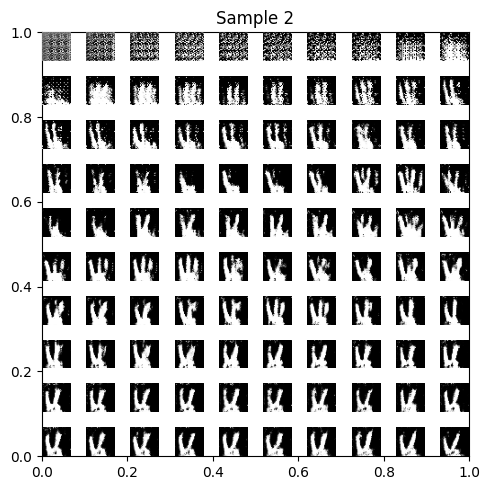

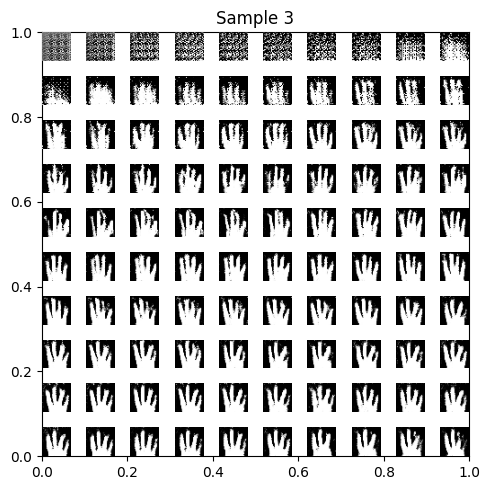

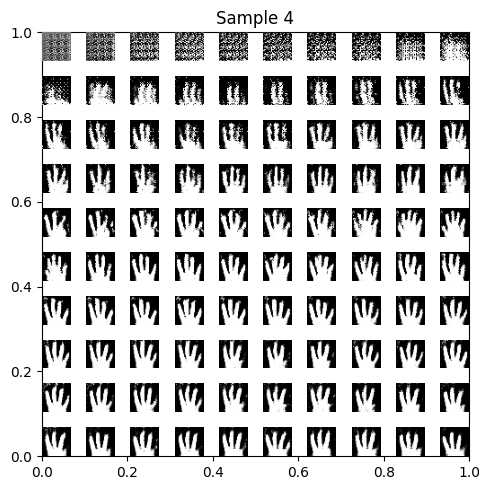

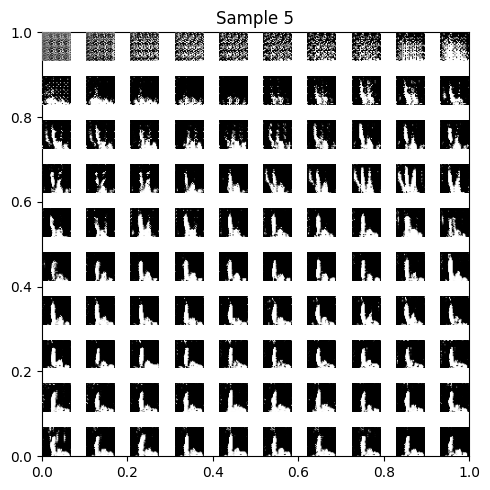

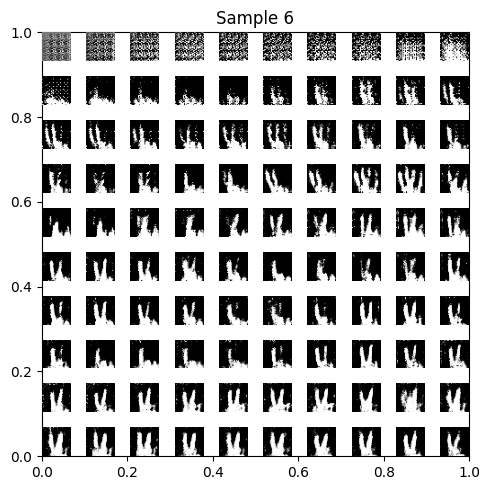

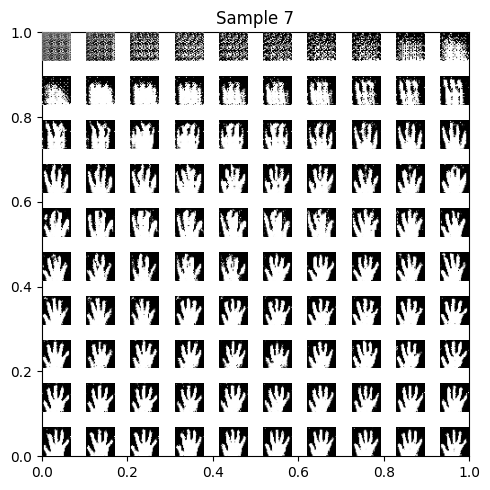

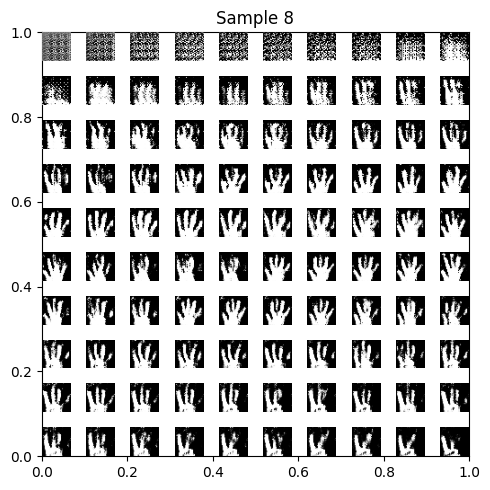

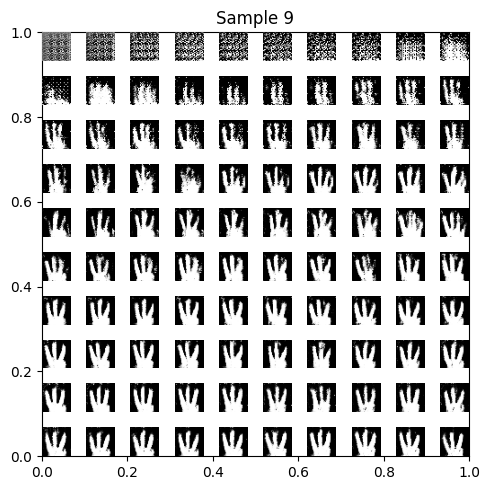

In [ ]:
for i in range(10):
  plot_sample(generator_generated_images2, i)
# plot_sample(1)

## Final generator result

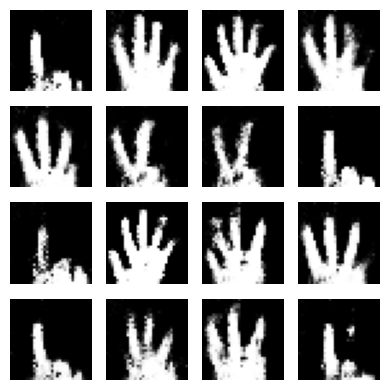

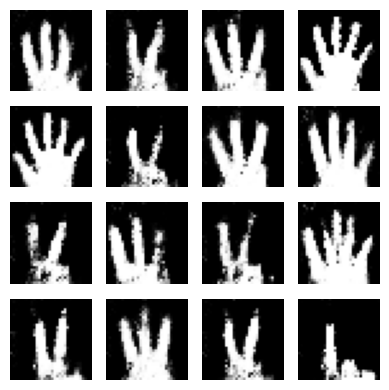

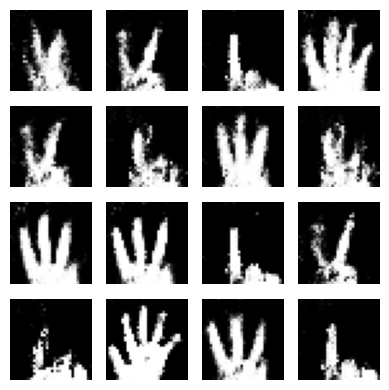

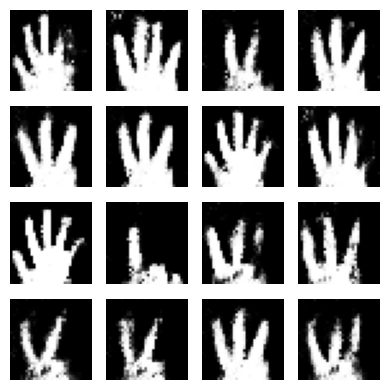

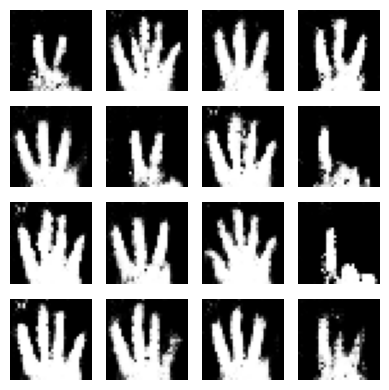

In [ ]:
for i in range(5):
  seed = tf.random.normal([16, NOISE_DIM])
  generate_and_show_images(generator2, seed)